In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score


### Creating Dataset

In [4]:
data = {
    "Load_Weight_kg": [10, 15, 8, 20, 12, 18, 5, 22, 14, 16],
    "Speed_m_per_s": [1.2, 1.5, 1.0, 1.8, 1.3, 1.6, 0.8, 2.0, 1.4, 1.7],
    "Terrain_Roughness": [3, 5, 2, 6, 4, 7, 3, 8, 5, 6],
    "Task_Duration_min": [15, 20, 10, 25, 18, 22, 12, 30, 19, 21],
    "Energy_Consumption_Wh": [120, 180, 90, 250, 150, 220, 80, 300, 170, 210]
}
data = pd.DataFrame(data)

In [5]:
data.head()

,Load_Weight_kg,Speed_m_per_s,Terrain_Roughness,Task_Duration_min,Energy_Consumption_Wh
0,10,1.2,3,15,120
1,15,1.5,5,20,180
2,8,1.0,2,10,90
3,20,1.8,6,25,250
4,12,1.3,4,18,150


### Train-Test Split

In [6]:
X = data.drop("Energy_Consumption_Wh", axis=1)  # all input features
y = data["Energy_Consumption_Wh"] # output feature


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training size:", len(X_train))
print("Testing size:", len(X_test))

Training size: 8
Testing size: 2


### Feature Scaling

In [7]:
scaler = StandardScaler()

# Fit only on training data (VERY IMPORTANT to avoid data leakage)
X_train_scaled = scaler.fit_transform(X_train)

# Apply same transformation to test data
X_test_scaled = scaler.transform(X_test)

### Training SVR Model

In [8]:
# Create SVR model with RBF kernel
svr_model = SVR(kernel='rbf')

# Train the model
svr_model.fit(X_train_scaled, y_train)

print("SVR model trained successfully!")

SVR model trained successfully!


### Predictions

In [9]:
new_data = pd.DataFrame([[25, 2.2, 7, 35]],
                        columns=["Load_Weight_kg",
                                 "Speed_m_per_s",
                                 "Terrain_Roughness",
                                 "Task_Duration_min"])
new_data_scaled = scaler.transform(new_data)

prediction = svr_model.predict(new_data_scaled)

print("Predicted Energy Consumption (Wh):", prediction[0])

Predicted Energy Consumption (Wh): 180.893219405397


### Visualization

   Load_Weight  Actual_Energy  Predicted_Energy
0           14            170        179.713403
1           15            180        180.413269


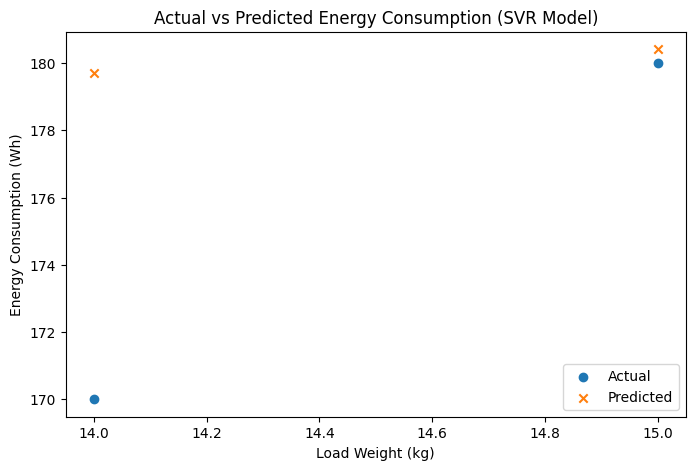

In [10]:
y_pred = svr_model.predict(X_test_scaled)
results = pd.DataFrame({
    "Load_Weight": X_test["Load_Weight_kg"].values,
    "Actual_Energy": y_test.values,
    "Predicted_Energy": y_pred
})

print(results)

plt.figure(figsize=(8,5))

plt.scatter(results["Load_Weight"], results["Actual_Energy"], label="Actual", marker='o')
plt.scatter(results["Load_Weight"], results["Predicted_Energy"], label="Predicted", marker='x')

plt.xlabel("Load Weight (kg)")
plt.ylabel("Energy Consumption (Wh)")
plt.title("Actual vs Predicted Energy Consumption (SVR Model)")
plt.legend()

plt.show()

In [11]:
# Fix other features at their mean values
speed_mean = X["Speed_m_per_s"].mean()
terrain_mean = X["Terrain_Roughness"].mean()
duration_mean = X["Task_Duration_min"].mean()

# High-resolution Load Weight range
load_range = np.linspace(X["Load_Weight_kg"].min(),
                         X["Load_Weight_kg"].max(),
                         200)  # finer steps

# Build dataset for prediction
X_smooth = pd.DataFrame({
    "Load_Weight_kg": load_range,
    "Speed_m_per_s": speed_mean,
    "Terrain_Roughness": terrain_mean,
    "Task_Duration_min": duration_mean
})

X_smooth_scaled = scaler.transform(X_smooth)
y_smooth_pred = svr_model.predict(X_smooth_scaled)

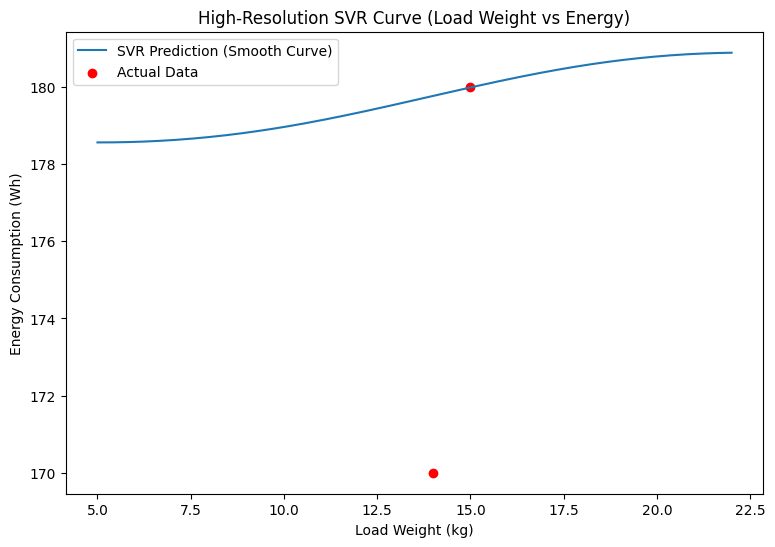

In [12]:
plt.figure(figsize=(9,6))

# Smooth SVR curve
plt.plot(load_range, y_smooth_pred, label="SVR Prediction (Smooth Curve)")

# Original test points
plt.scatter(X_test["Load_Weight_kg"], y_test, color='red', label="Actual Data")

plt.xlabel("Load Weight (kg)")
plt.ylabel("Energy Consumption (Wh)")
plt.title("High-Resolution SVR Curve (Load Weight vs Energy)")
plt.legend()

plt.show()

### Model Evaluation

In [14]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
print("R2 Score:", r2)

Mean Squared Error (MSE): 47.26049282170618
R2 Score: -0.8904197128682472


### Training Linear Regression to compare with SVR

In [15]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

# SVR metrics
mse_svr = mean_squared_error(y_test, y_pred)
r2_svr = r2_score(y_test, y_pred)

# Linear Regression metrics
mse_lr = mean_squared_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("=== SVR Model ===")
print("MSE:", mse_svr)
print("R2:", r2_svr)

print("\n=== Linear Regression ===")
print("MSE:", mse_lr)
print("R2:", r2_lr)

=== SVR Model ===
MSE: 47.26049282170618
R2: -0.8904197128682472

=== Linear Regression ===
MSE: 70.65189898206445
R2: -1.8260759592825782


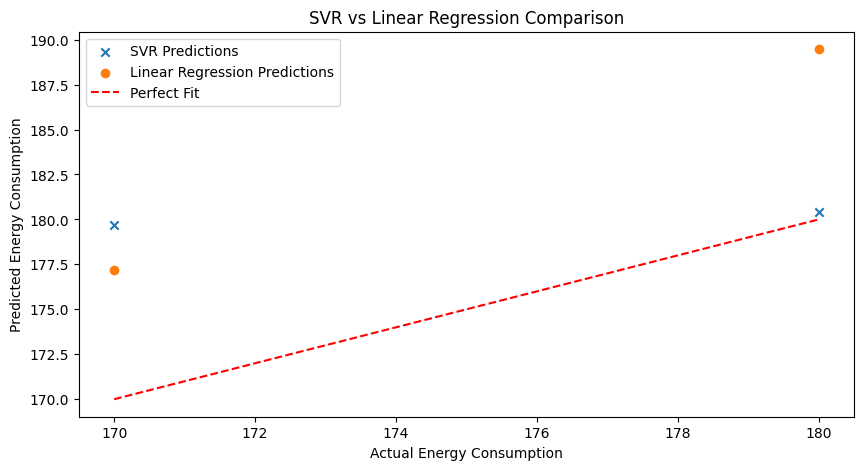

In [16]:
plt.figure(figsize=(10,5))

plt.scatter(y_test, y_pred, label="SVR Predictions", marker='x')
plt.scatter(y_test, y_pred_lr, label="Linear Regression Predictions", marker='o')

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--', label="Perfect Fit")

plt.xlabel("Actual Energy Consumption")
plt.ylabel("Predicted Energy Consumption")
plt.title("SVR vs Linear Regression Comparison")
plt.legend()

plt.show()

### Brief interpretation of results

Both models are not doing well with R² values. This means they are not better than guessing the average energy for all cases. The problem is that the dataset is too small and not detailed enough for the models to learn patterns.

However:

* SVR does better than Linear Regression.

* SVR has an R² of -0.89 and an MSE of 47.26.

* Linear Regression has an R² of -1.83 and an MSE of 70.65.

SVR is a bit better at capturing relationships.. Both models are still not doing well because of limited data and weak generalization.

#### **How terrain roughness affects energy consumption**

From the data. What makes sense:

* Rough terrain (1 to 10) makes it harder to move

* The robot needs power to keep going

* Energy consumption goes up quickly on rough terrain

Terrain roughness makes energy consumption go up more when combined with heavy load and high speed.

#### **Using this in systems**

A) Planning the path

This model can help:

* Figure out the energy cost of different routes

* Choose paths that use energy, not just shorter paths

For example:

* A flat but longer path might use energy

* A rough but short path might use energy

B) Controlling the robot to save energy

The model can be used in robot controllers to:

* Adjust speed based on predicted energy use

* Slow down on terrain to save energy

* Optimize how the robot handles its load

Example control logic:

If predicted energy use is too high:

* slow down

* change path

* or plan for a recharge

#### **Final summary**

The SVR model did better than Linear Regression at capturing relationships, between factors and energy consumption.. Both models still did not do well because of the small dataset. Rough terrain greatly increases energy consumption with heavy load and high speed. Such models can be used in path planning systems to minimize energy use and in controllers to adjust movement strategies.